# Exercise 1: Linear regression
Initially we will work on 2D points and then expand it out to 3D.

We'll do the necessary imports for the notebook and then generate some data.

The data generation is as follows:
$$
x \sim \mathcal{N}(\mu_x, \sigma_x^2)
$$ 
with $\mu_x=1.5$ being the mean and $\sigma_x = 2.5$ being the standard deviation.

We also add a normally distributed error term with zero mean $\mu_\epsilon=0$ and standard deviation
$\sigma_\epsilon=0.5$.

In [5]:
import numpy as np
import open3d as o3d
from matplotlib import pyplot as plt
from sklearn.linear_model import LinearRegression
from mpl_toolkits.mplot3d import Axes3D

In [8]:
# Why np.random.seed(0): fixes the random number generator's starting state so
# that re-running this cell always produces the exact same "random" x, residual,
# and y values. Without this, results would differ every run.
# Why this data-generation process: x is drawn from a normal distribution, then
# y is built as a known true linear relationship (y = 2 + 0.3*x) plus random
# noise (res). Since we know the true underlying intercept (2) and slope (0.3),
# we can later check whether our regression methods recover something close to
# these true values from the noisy data alone.
# Generate "random" data.
np.random.seed(0)
# Array of 100 values with mean = 1.5, stddev = 2.5.
x = np.random.normal(1.5, 2.5, 100)
# Generate 100 residual terms (mean=0, std=0.5).
res = np.random.normal(0, 0.5, 100)
# Actual values of Y.
y = 2 + 0.3 * x + res

We can use the linear regression algorithm from the `sklearn` package.
Here, we setup the model to fit `x` to `y`.

In [9]:
# Why reshape x first: sklearn's fit() expects its input features as a 2D array
# of shape (n_samples, n_features), even when there's only one feature. x on
# its own is a flat 1D array of shape (100,), so reshape(-1, 1) turns it into
# the required (100, 1) column-vector shape without needing to manually specify
# how many rows there are.
# Fit needs x in this shape.
x_r = x.reshape(-1, 1)
# Initialise and fit model.
lm = LinearRegression()
model = lm.fit(x_r, y)

We can now predict new outcomes given new data.

In [15]:
# Use the fitted model to predict a new y value for a single new x point.
# Why draw tst_x this way: 2.5*randn(1)+1.5 generates one more sample from the
# exact same distribution x itself was drawn from (mean 1.5, std 2.5), simulating
# "a new, previously unseen data point" to test the model's prediction on, then
# reshaping it to the (1, 1) shape model.predict() expects (matching x_r's shape
# from the fitting step).
# Draw a new datapoint.
tst_x = 2.5 * np.random.randn(1).reshape(-1, 1) + 1.5
print(tst_x)
resulting_y = model.predict(tst_x)
print(resulting_y)

[[3.46450957]]
[3.12199465]


Drawing 200 new samples and plotting them as a line shows us that we have gotten a decent fit.

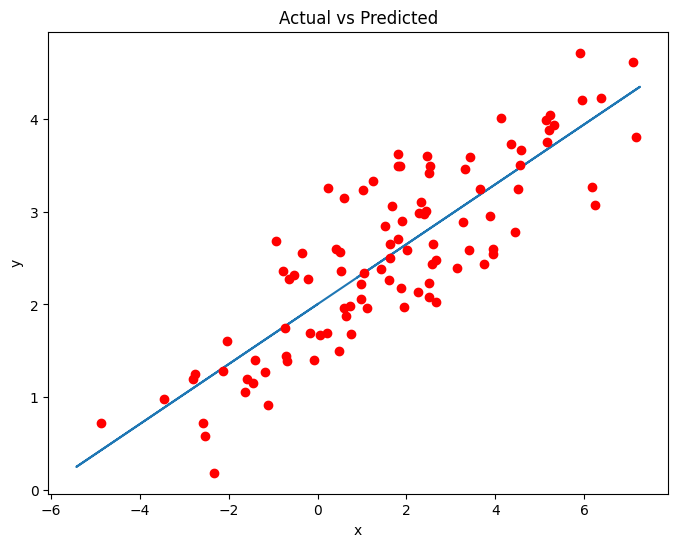

In [11]:
# Why generate 200 new x values across the same distribution: sampling many new
# points and plotting the model's predictions for all of them traces out the
# model's fitted regression line smoothly across the range of x. This is much
# easier to visually judge for "does this look like a good fit" than checking
# individual predictions one at a time.
# How the plot is built: the blue line (plt.plot(new_x, predicted)) shows what
# the model predicts across a range of x values, while the red dots
# (plt.plot(x, y, 'ro')) show the actual original training data, so you can
# compare how well the fitted line tracks the real data's overall trend.
new_x = 2.5 * np.random.randn(200).reshape(-1, 1) + 1.5
predicted = model.predict(new_x)
plt.figure(figsize=(8, 6))
plt.plot(new_x, predicted)  # Regression line.
plt.plot(x, y, "ro")  # Scatter plot showing actual data.
plt.title("Actual vs Predicted")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## Exercises
### A
Using [Ordinary Least Squares (OLS)](https://en.wikipedia.org/wiki/Ordinary_least_squares), attempt to get a regression line that is equal to the one `sklearn` provides.

Assuming that the data is modeled by the following, having $N$ data points available:
$$
\underbrace{\hat{\mathbf{y}}}_{N \times 1} = \underbrace{\mathbf{X}}_{N\times (K+1)} \underbrace{\beta^\text{*}}_{(K+1) \times 1} + \underbrace{\varepsilon}_{N \times 1} 
$$
Ordinary Least squares optimizes the parameters $\beta$ such that the resdiual error (measured by the Sum of Squared Errors (SSE) objective/loss function $L$) is minimal (regression). That is:
$$
L(\mathbf{X}_i, y_i;\mathbf{\beta}) = \sum_{i=1}^N (y_i - \hat{y_i})^2 \\
\beta^\text{*} = \argmin_\beta L(\mathbf{X}, \mathbf{y};\beta)
$$
where $y_i$ is the true value and $\hat{y_i}$ is the predicted value given a point $\mathbf{X}_i \in \mathbb{R}$.
We won't go into detail here how to solve this optimization problem but instead give you the solution directly:
$$
\beta^\text{*} = (\mathbf{X}^\top \mathbf{X})^{-1}\mathbf{X}^\top \mathbf{y}
$$
Using this, you need to organize your data in matrices of shapes $(N, K+1)$ for $\mathbf{X}$ with $N$ being the number of data points and $K$ being the dimension of $\mathbf{X_i}$, i.e. $\mathbf{X}_i \in \mathbb{R}^K$. The $+1$ is for the intercept, so $\beta_0$ will be our intercept term. For $\mathbf{y}$, you need to make sure it is of shape $(N, 1)$. So, the first row of $\mathbf{X}$ would look like this if $\mathbf{X}_i \in \mathbb{R}$:
$$
\mathbf{X_0} = \begin{bmatrix}1 & x_{1,0}\end{bmatrix}
$$
<details open>
<summary>If the above formulation is too complicated, here's another formulation</summary>
<br>
Assuming
Yₑ = α + β X

![ols.gif](ols.gif "ols")

- β = Cov(X, Y) / Var(X).
- α = mean(Y)-β*mean(X)

</br>
</details>

In [12]:
# Why build a "design matrix" X with a column of ones: the normal equation's
# solution assumes the model is written as y = X @ beta (matrix form), where
# beta includes both the slope and the intercept as one combined vector.
# Prepending a column of all 1s to X is what lets the intercept term be estimated
# by the same single matrix equation as the slope.
# Why beta = inv(X.T @ X) @ X.T @ Y: this is a direct implementation of the
# closed-form OLS solution given in the markdown above (beta* = (X^T X)^-1 X^T y).
# It finds the intercept/slope values that minimize the sum of squared differences
# between the true y values and the model's predicted values, without needing
# any iterative optimization.
# Why beta.ravel(): np.linalg.inv(...) @ ... produces a (2, 1) column-vector
# result; ravel() flattens it to a plain 1D array so its two values can be
# unpacked directly into separate intercept_ols/slope_ols variables.
N = x.shape[0]

# Design matrix X: first column is all ones (intercept), second column is x.
X = np.hstack([np.ones((N, 1)), x.reshape(-1, 1)])
Y = y.reshape(-1, 1)

# Normal equation: beta = (X^T X)^-1 X^T y.
beta = np.linalg.inv(X.T @ X) @ X.T @ Y
intercept_ols, slope_ols = beta.ravel()

print(
    "OLS      -> intercept: {:.6f}, slope: {:.6f}".format(
        intercept_ols, slope_ols
    )
)
print(
    "sklearn  -> intercept: {:.6f}, slope: {:.6f}".format(
        model.intercept_, model.coef_[0]
    )
)

OLS      -> intercept: 2.003167, slope: 0.322940
sklearn  -> intercept: 2.003167, slope: 0.322940


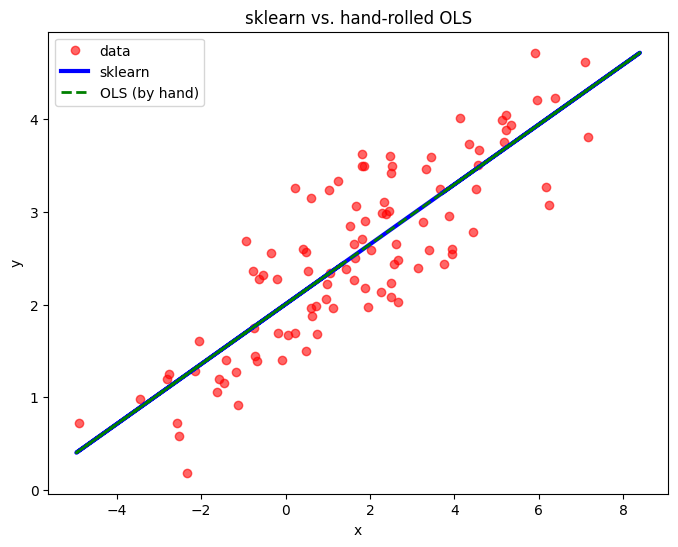

In [16]:
# Why plot both lines together rather than separately: if the two regression
# lines are actually equivalent, they should visually overlap almost perfectly.
# Any visible gap between the solid blue (sklearn) and dashed green (OLS) lines
# would be an obvious red flag that something in the manual OLS implementation d
# oesn't match.
new_x = 2.5 * np.random.randn(200).reshape(-1, 1) + 1.5
predicted_sklearn = model.predict(new_x)
predicted_ols = intercept_ols + slope_ols * new_x

plt.figure(figsize=(8, 6))
plt.plot(x, y, "ro", label="data", alpha=0.6)
plt.plot(new_x, predicted_sklearn, "b-", linewidth=3, label="sklearn")
plt.plot(new_x, predicted_ols, "g--", linewidth=2, label="OLS (by hand)")
plt.title("sklearn vs. hand-rolled OLS")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


### B
Extend what we have shown above to 3D predict a plane using Linear regression given a point cloud.

Planes can be plotted with 
```{Python}
x = np.linspace(start, end, n)
y = np.linspace(start, end, n)
xx, yy = np.meshgrid(x_t, y_t)

ax.plot_surface(xx, yy, predicted_zz, alpha=0.2)
```

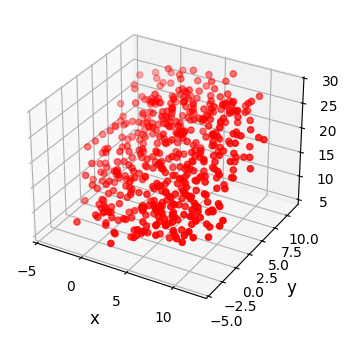

In [17]:
# Why move from synthetic 2D data to a loaded 3D point cloud: this exercise's
# actual data is noisy 3D data. The task is to discover whatever planar structure
# exists in these points using the same linear regression principles just
# demonstrated in 2D, now extended to 3D.
# Why np.asarray(pc.points): open3d point clouds store their point data in their
# own internal PointCloud.points structure; converting it to a plain numpy array
# is what lets us slice out individual x/y/z columns and feed the data into
# numpy/sklearn's linear algebra functions.
# Creating a pointcloud.
pc = o3d.io.read_point_cloud("TestData/spread_points.ply")
xyz = np.asarray(pc.points)

fig = plt.figure(figsize=(6, 4))
ax = plt.axes(projection="3d")
ax.scatter3D(xyz[:, 0], xyz[:, 1], xyz[:, 2], color="red")
ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.set_zlabel("z", fontsize=12)
plt.show()

In [18]:
# Split the loaded point cloud into inputs (x, y) and target (z), ready for
# fitting a plane.
# Why z is the target and x/y are the inputs: fitting "a plane" here means
# modeling z as a linear function of x and y (z = intercept + coef_x*x + coef_y*y).
# Conceptually the direct 3D extension of the 2D case's y = intercept + slope*x,
# just with one extra input dimension.
## We want to predict Z.
xy = xyz[:, :2]  # Our inputs.
z = xyz[:, 2].reshape(-1, 1)  # Our targets.

In [19]:
# Why the design matrix is now [1, x, y] instead of [1, x] : fitting a plane
# needs three parameters instead of two. An intercept, plus one coefficient for
# each of the two input dimensions (x and y). So the design matrix gains one
# extra column (for the y feature) compared to the 2D case, but the underlying
# normal-equation math (beta = inv(X^T X) @ X^T @ Z) is otherwise identical,
# showing how the same OLS formula generalizes to higher dimensions.
# Why the sklearn cross-check handles lm3.intercept_ differently: when sklearn's
# target 'Z' is passed in as a 2D (N, 1) array rather than a flat 1D array,
# LinearRegression sometimes returns intercept_ as a length-1 array rather than
# a plain scalar float. This conditional simply unwraps it to a scalar either
# way, so the print statement formats correctly regardless of which shape
# sklearn happened to return.
N3 = xy.shape[0]

X3 = np.hstack([np.ones((N3, 1)), xy])
Z = z

beta3 = np.linalg.inv(X3.T @ X3) @ X3.T @ Z
intercept3, coef_x, coef_y = beta3.ravel()

print(
    "OLS plane -> z = {:.4f} + {:.4f}*x + {:.4f}*y".format(
        intercept3, coef_x, coef_y
    )
)

lm3 = LinearRegression().fit(xy, z)
print(
    "sklearn   -> z = {:.4f} + {:.4f}*x + {:.4f}*y".format(
        lm3.intercept_[0]
        if hasattr(lm3.intercept_, "__len__")
        else lm3.intercept_,
        lm3.coef_[0][0],
        lm3.coef_[0][1],
    )
)

OLS plane -> z = 10.8136 + 0.0324*x + 1.5270*y
sklearn   -> z = 10.8136 + 0.0324*x + 1.5270*y


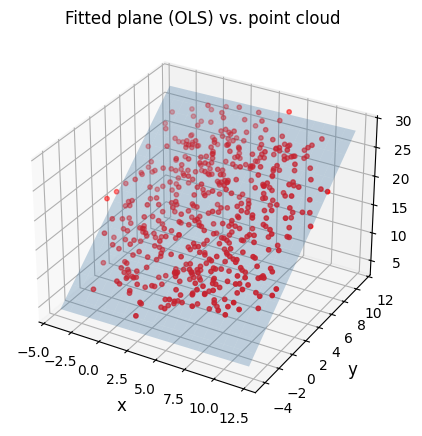

In [20]:
# Why build a meshgrid (xx, yy) spanning the data's x/y range: a plane can't be
# drawn directly from just its 3 coefficients. plot_surface() needs an actual
# grid of (x, y) coordinates to evaluate the fitted plane equation at, in order
# to draw a continuous surface; np.meshgrid() creates that grid across the
# observed data's x and y extent.
# Why predicted_zz = intercept3 + coef_x*xx + coef_y*yy: this evaluates the
# fitted plane equation from Exercise B at every point of that grid, producing
# the corresponding z-height of the fitted plane across the whole grid, which is
# what plot_surface() needs to draw the semi-transparent blue plane overlaid on
# top of the red scattered data points.
x_t = np.linspace(xyz[:, 0].min(), xyz[:, 0].max(), 20)
y_t = np.linspace(xyz[:, 1].min(), xyz[:, 1].max(), 20)
xx, yy = np.meshgrid(x_t, y_t)

predicted_zz = intercept3 + coef_x * xx + coef_y * yy

fig = plt.figure(figsize=(7, 5))
ax = plt.axes(projection="3d")
ax.scatter3D(
    xyz[:, 0], xyz[:, 1], xyz[:, 2], color="red", s=10, label="points"
)
ax.plot_surface(xx, yy, predicted_zz, alpha=0.3, color="steelblue")
ax.set_xlabel("x", fontsize=12)
ax.set_ylabel("y", fontsize=12)
ax.set_zlabel("z", fontsize=12)
ax.set_title("Fitted plane (OLS) vs. point cloud")
plt.show()